# Telecom Churn Intelligence Platform
## 02 - Machine Learning Modeling

### Objective
Build and evaluate machine learning models to predict customer churn.

### Main Research Question
Can we identify customers at risk of churn, understand why they are at risk,
and determine whether geographic information adds useful predictive value?

In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

## 1. Load the Dataset

We reload the original dataset rather than using the dataframe from the EDA notebook.
This keeps the ML workflow independent and reproducible.

In [3]:
df = pd.read_excel("../data/raw/Telco_customer_churn.xlsx")

df.shape

(7043, 33)

In [4]:
target = "Churn Label"

y = df[target]

y.value_counts()

Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

In [5]:
columns_to_drop = [
    "CustomerID",
    "Count",
    "Country",
    "State",
    "Churn Value",
    "Churn Score",
    "CLTV",
    "Churn Reason"
]

ml_df = df.drop(columns = columns_to_drop)
ml_df.shape

(7043, 25)

In [6]:
ml_df.columns

Index(['City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender',
       'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months',
       'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label'],
      dtype='str')

Create X and y

In [7]:
target = "Churn Label"

X = ml_df.drop(columns=[target])

y = ml_df[target]

print("X shape:",X.shape)
print("y shape:",y.shape)

X shape: (7043, 24)
y shape: (7043,)


In [8]:
y.value_counts()

Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

In [9]:
y.value_counts(normalize=True) * 100

Churn Label
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

Train/Test Split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20,
    random_state=42,
    stratify = y
)

In [11]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (5634, 24)
X_test : (1409, 24)
y_train: (5634,)
y_test : (1409,)


In [12]:
numeric_features = X_train.select_dtypes(
    include=["int64","float64"]
).columns.tolist()

numeric_features

['Zip Code', 'Latitude', 'Longitude', 'Tenure Months', 'Monthly Charges']

In [13]:
categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

categorical_features

C:\Users\HP\AppData\Local\Temp\ipykernel_5860\1640599611.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


['City',
 'Lat Long',
 'Gender',
 'Senior Citizen',
 'Partner',
 'Dependents',
 'Phone Service',
 'Multiple Lines',
 'Internet Service',
 'Online Security',
 'Online Backup',
 'Device Protection',
 'Tech Support',
 'Streaming TV',
 'Streaming Movies',
 'Contract',
 'Paperless Billing',
 'Payment Method',
 'Total Charges']

In [14]:
X_train["Total Charges"] = pd.to_numeric(
    X_train["Total Charges"],
    errors="coerce"
)

X_test["Total Charges"] = pd.to_numeric(
    X_test["Total Charges"],
    errors="coerce"
)

In [15]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

Numerical features:
['Zip Code', 'Latitude', 'Longitude', 'Tenure Months', 'Monthly Charges', 'Total Charges']


In [16]:
categorical_features = X_train.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

Categorical features:
['City', 'Lat Long', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


In [17]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

In [18]:
from sklearn.pipeline import Pipeline
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [19]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [20]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [21]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [22]:
print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original test shape:", X_test.shape)
print("Processed test shape:", X_test_processed.shape)

Original training shape: (5634, 24)
Processed training shape: (5634, 2827)
Original test shape: (1409, 24)
Processed test shape: (1409, 2827)


In [23]:
feature_names = preprocessor.get_feature_names_out()

print("Number of processed features:", len(feature_names))
print("\nFirst 30 features:")
print(feature_names[:30])

Number of processed features: 2827

First 30 features:
['num__Zip Code' 'num__Latitude' 'num__Longitude' 'num__Tenure Months'
 'num__Monthly Charges' 'num__Total Charges' 'cat__City_Acampo'
 'cat__City_Acton' 'cat__City_Adelanto' 'cat__City_Adin'
 'cat__City_Agoura Hills' 'cat__City_Aguanga' 'cat__City_Ahwahnee'
 'cat__City_Alameda' 'cat__City_Alamo' 'cat__City_Albany'
 'cat__City_Albion' 'cat__City_Alderpoint' 'cat__City_Alhambra'
 'cat__City_Aliso Viejo' 'cat__City_Alleghany' 'cat__City_Alpaugh'
 'cat__City_Alpine' 'cat__City_Alta' 'cat__City_Altadena'
 'cat__City_Alturas' 'cat__City_Alviso' 'cat__City_Amador City'
 'cat__City_Amboy' 'cat__City_Anaheim']


In [24]:
from sklearn.linear_model import LogisticRegression


In [25]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [26]:
logistic_model.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [27]:
y_pred = logistic_model.predict(X_test_processed)

In [28]:
print(y_pred[:20])

['No' 'Yes' 'No' 'No' 'No' 'Yes' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes'
 'No' 'No' 'No' 'Yes' 'No' 'No']


In [29]:
from sklearn.metrics import confusion_matrix

In [30]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[911 124]
 [174 200]]


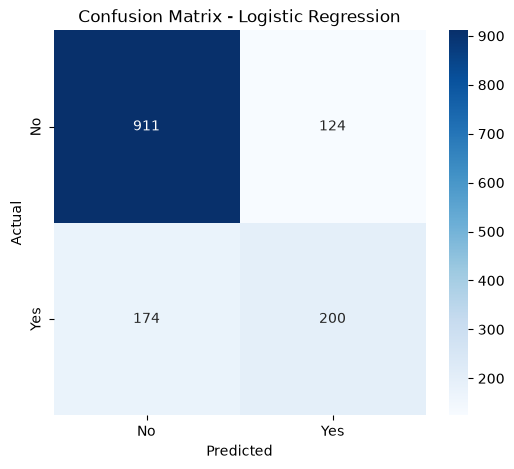

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label="Yes")
recall = recall_score(y_test, y_pred, pos_label="Yes")
f1 = f1_score(y_test, y_pred, pos_label="Yes")

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.7885024840312278
Precision: 0.6172839506172839
Recall   : 0.5347593582887701
F1 Score : 0.5730659025787965


In [33]:
y_proba = logistic_model.predict_proba(X_test_processed)

print(y_proba[:5])

[[0.94376815 0.05623185]
 [0.20788827 0.79211173]
 [0.94137104 0.05862896]
 [0.64681569 0.35318431]
 [0.9896384  0.0103616 ]]


In [34]:
print(logistic_model.classes_)

['No' 'Yes']


In [35]:
from sklearn.metrics import roc_auc_score

In [36]:
y_proba_yes = y_proba[:, 1]

In [37]:
roc_auc = roc_auc_score(y_test, y_proba_yes)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.8335813376734094


In [38]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.84      0.88      0.86      1035
         Yes       0.62      0.53      0.57       374

    accuracy                           0.79      1409
   macro avg       0.73      0.71      0.72      1409
weighted avg       0.78      0.79      0.78      1409



In [39]:
baseline_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1,
    "ROC-AUC": roc_auc
}

baseline_results

{'Model': 'Logistic Regression',
 'Accuracy': 0.7885024840312278,
 'Precision': 0.6172839506172839,
 'Recall': 0.5347593582887701,
 'F1 Score': 0.5730659025787965,
 'ROC-AUC': 0.8335813376734094}

KNN Classification 

In [40]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(X_train_processed, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](2,)","['No','Yes']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [41]:
y_pred_knn = knn_model.predict(X_test_processed)

print(y_pred_knn[:20])

['No' 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes' 'No' 'No' 'Yes' 'No' 'No' 'No'
 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No']


In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

knn_accuracy = accuracy_score(y_test, y_pred_knn)
knn_precision = precision_score(y_test, y_pred_knn, pos_label="Yes")
knn_recall = recall_score(y_test, y_pred_knn, pos_label="Yes")
knn_f1 = f1_score(y_test, y_pred_knn, pos_label="Yes")

print("KNN Accuracy :", knn_accuracy)
print("KNN Precision:", knn_precision)
print("KNN Recall   :", knn_recall)
print("KNN F1 Score :", knn_f1)

KNN Accuracy : 0.7480482611781405
KNN Precision: 0.524547803617571
KNN Recall   : 0.5427807486631016
KNN F1 Score : 0.533508541392904


In [43]:
print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

          No       0.83      0.82      0.83      1035
         Yes       0.52      0.54      0.53       374

    accuracy                           0.75      1409
   macro avg       0.68      0.68      0.68      1409
weighted avg       0.75      0.75      0.75      1409



In [44]:
from sklearn.metrics import confusion_matrix

cm_knn = confusion_matrix(y_test, y_pred_knn)

print(cm_knn)

[[851 184]
 [171 203]]


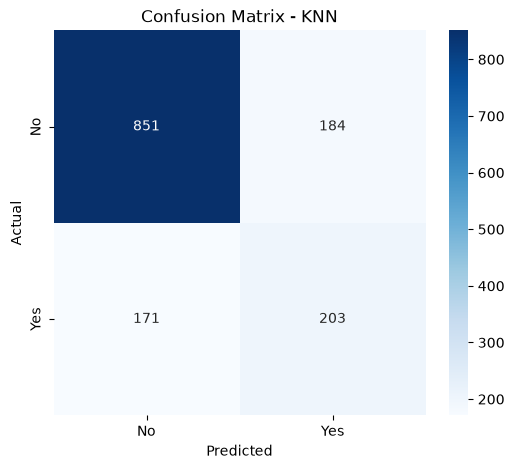

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - KNN")
plt.show()


In [46]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

decision_tree.fit(X_train_processed, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

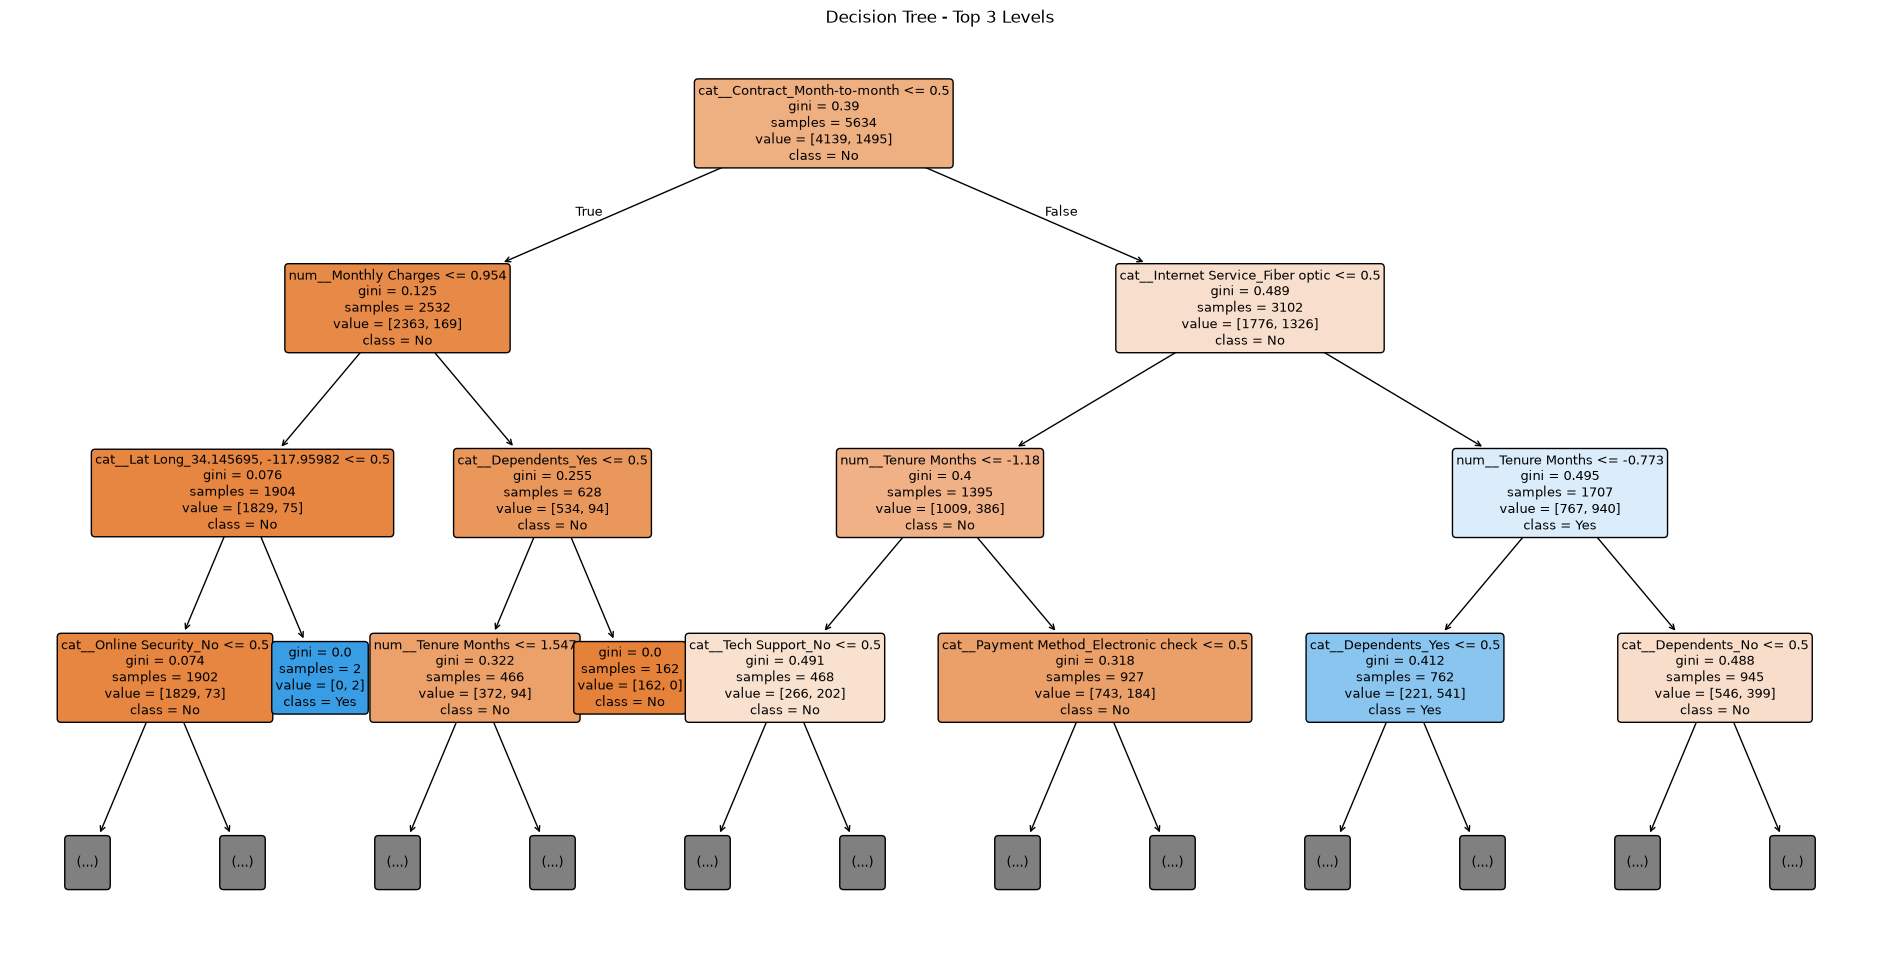

In [47]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(24, 12))

plot_tree(
    decision_tree,
    max_depth=3,
    feature_names=feature_names,
    class_names=decision_tree.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree - Top 3 Levels")
plt.show()

In [48]:
y_pred_tree = decision_tree.predict(X_test_processed)

print(y_pred_tree[:20])

['No' 'Yes' 'No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes'
 'No' 'No' 'No' 'No' 'No' 'No']


In [49]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

tree_accuracy = accuracy_score(y_test, y_pred_tree)
tree_precision = precision_score(
    y_test, y_pred_tree, pos_label="Yes"
)
tree_recall = recall_score(
    y_test, y_pred_tree, pos_label="Yes"
)
tree_f1 = f1_score(
    y_test, y_pred_tree, pos_label="Yes"
)

print("Decision Tree Accuracy :", tree_accuracy)
print("Decision Tree Precision:", tree_precision)
print("Decision Tree Recall   :", tree_recall)
print("Decision Tree F1 Score :", tree_f1)

Decision Tree Accuracy : 0.794180269694819
Decision Tree Precision: 0.6141304347826086
Decision Tree Recall   : 0.6042780748663101
Decision Tree F1 Score : 0.6091644204851752


In [50]:
cm_tree = confusion_matrix(y_test, y_pred_tree)

print(cm_tree)

[[893 142]
 [148 226]]


In [51]:
y_proba_tree = decision_tree.predict_proba(X_test_processed)

print(y_proba_tree[:5])
print(decision_tree.classes_)

[[0.93913043 0.06086957]
 [0.31619048 0.68380952]
 [0.97801466 0.02198534]
 [0.45652174 0.54347826]
 [0.97801466 0.02198534]]
['No' 'Yes']


In [52]:
from sklearn.metrics import roc_auc_score

y_proba_tree_yes = y_proba_tree[:, 1]

tree_roc_auc = roc_auc_score(
    y_test,
    y_proba_tree_yes
)

print("Decision Tree ROC-AUC:", tree_roc_auc)

Decision Tree ROC-AUC: 0.835543413676406


RANDOM FOREST 

In [53]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train_processed, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [54]:
y_pred_rf = random_forest.predict(X_test_processed)

print(y_pred_rf[:20])

['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes'
 'No' 'No' 'No' 'No' 'No' 'No']


In [55]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, pos_label="Yes")
rf_recall = recall_score(y_test, y_pred_rf, pos_label="Yes")
rf_f1 = f1_score(y_test, y_pred_rf, pos_label="Yes")

print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1 Score :", rf_f1)

Accuracy : 0.7955997161107168
Precision: 0.6535714285714286
Recall   : 0.4893048128342246
F1 Score : 0.5596330275229358


In [56]:
y_proba_rf = random_forest.predict_proba(X_test_processed)

print(y_proba_rf[:5])
print(random_forest.classes_)

[[0.99  0.01 ]
 [0.365 0.635]
 [0.96  0.04 ]
 [0.655 0.345]
 [0.98  0.02 ]]
['No' 'Yes']


In [57]:
from sklearn.metrics import roc_auc_score

y_proba_rf_yes = y_proba_rf[:, 1]

rf_roc_auc = roc_auc_score(
    y_test,
    y_proba_rf_yes
)

print("Random Forest ROC-AUC:", rf_roc_auc)

Random Forest ROC-AUC: 0.8413650572218347


In [58]:
from sklearn.ensemble import GradientBoostingClassifier

gradient_boosting = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gradient_boosting.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [59]:
y_pred_gb = gradient_boosting.predict(X_test_processed)

print(y_pred_gb[:20])

['No' 'Yes' 'No' 'No' 'No' 'Yes' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes'
 'No' 'No' 'No' 'No' 'No' 'No']


In [60]:
gb_accuracy = accuracy_score(y_test, y_pred_gb)
gb_precision = precision_score(y_test, y_pred_gb, pos_label="Yes")
gb_recall = recall_score(y_test, y_pred_gb, pos_label="Yes")
gb_f1 = f1_score(y_test, y_pred_gb, pos_label="Yes")

print("Accuracy :", gb_accuracy)
print("Precision:", gb_precision)
print("Recall   :", gb_recall)
print("F1 Score :", gb_f1)

Accuracy : 0.8048261178140526
Precision: 0.6666666666666666
Recall   : 0.5294117647058824
F1 Score : 0.5901639344262295


In [61]:
y_proba_gb = gradient_boosting.predict_proba(X_test_processed)

print(y_proba_gb[:5])
print(gradient_boosting.classes_)

[[0.9378409  0.0621591 ]
 [0.22454888 0.77545112]
 [0.93448054 0.06551946]
 [0.59171251 0.40828749]
 [0.95395191 0.04604809]]
['No' 'Yes']


In [62]:
y_proba_gb_yes = y_proba_gb[:, 1]

gb_roc_auc = roc_auc_score(
    y_test,
    y_proba_gb_yes
)

print("Gradient Boosting ROC-AUC:", gb_roc_auc)

Gradient Boosting ROC-AUC: 0.8517424888268879


In [63]:
gb_accuracy = accuracy_score(y_test, y_pred_gb)
gb_precision = precision_score(y_test, y_pred_gb, pos_label="Yes")
gb_recall = recall_score(y_test, y_pred_gb, pos_label="Yes")
gb_f1 = f1_score(y_test, y_pred_gb, pos_label="Yes")

print("Accuracy :", gb_accuracy)
print("Precision:", gb_precision)
print("Recall   :", gb_recall)
print("F1 Score :", gb_f1)

Accuracy : 0.8048261178140526
Precision: 0.6666666666666666
Recall   : 0.5294117647058824
F1 Score : 0.5901639344262295


In [64]:
# Geographic features
geo_features = [
    "City",
    "Zip Code",
    "Lat Long",
    "Latitude",
    "Longitude"
]

# Check them
print("Geographic features:")
print(geo_features)

Geographic features:
['City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude']


In [65]:
# Remove geographic features for Model A

model_a_df = ml_df.drop(columns=geo_features)

print("Model A shape:", model_a_df.shape)
print("\nModel A columns:")
print(model_a_df.columns.tolist())

Model A shape: (7043, 20)

Model A columns:
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label']


In [66]:
# Remove geographic features for Model A

model_a_df = ml_df.drop(columns=geo_features)

print("Model A shape:", model_a_df.shape)
print("\nModel A columns:")
print(model_a_df.columns.tolist())

Model A shape: (7043, 20)

Model A columns:
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label']


In [67]:
target = "Churn Label"

X_A = model_a_df.drop(columns=[target])
y_A = model_a_df[target]

print("X_A shape:", X_A.shape)
print("y_A shape:", y_A.shape)

print("\nTarget distribution:")
print(y_A.value_counts())

X_A shape: (7043, 19)
y_A shape: (7043,)

Target distribution:
Churn Label
No     5174
Yes    1869
Name: count, dtype: int64


In [68]:
from sklearn.model_selection import train_test_split

X_A_train, X_A_test, y_A_train, y_A_test = train_test_split(
    X_A,
    y_A,
    test_size=0.20,
    random_state=42,
    stratify=y_A
)

print("X_A_train:", X_A_train.shape)
print("X_A_test :", X_A_test.shape)
print("y_A_train:", y_A_train.shape)
print("y_A_test :", y_A_test.shape)

X_A_train: (5634, 19)
X_A_test : (1409, 19)
y_A_train: (5634,)
y_A_test : (1409,)


In [69]:
numeric_features_A = X_A_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features_A = X_A_train.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print("Numerical features:")
print(numeric_features_A)

print("\nCategorical features:")
print(categorical_features_A)

Numerical features:
['Tenure Months', 'Monthly Charges']

Categorical features:
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Total Charges']


In [70]:
# Convert Total Charges from text to numeric
X_A_train["Total Charges"] = pd.to_numeric(
    X_A_train["Total Charges"],
    errors="coerce"
)

X_A_test["Total Charges"] = pd.to_numeric(
    X_A_test["Total Charges"],
    errors="coerce"
)

In [71]:
numeric_features_A = X_A_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features_A = X_A_train.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print("Numerical features:")
print(numeric_features_A)

print("\nCategorical features:")
print(categorical_features_A)

Numerical features:
['Tenure Months', 'Monthly Charges', 'Total Charges']

Categorical features:
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


In [72]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numeric_transformer_A = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer_A = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both
preprocessor_A = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_A, numeric_features_A),
        ("cat", categorical_transformer_A, categorical_features_A)
    ]
)

print("Model A preprocessing pipeline created.")

Model A preprocessing pipeline created.


In [73]:
X_A_train_processed = preprocessor_A.fit_transform(X_A_train)

X_A_test_processed = preprocessor_A.transform(X_A_test)

print("X_A_train_processed shape:", X_A_train_processed.shape)
print("X_A_test_processed shape :", X_A_test_processed.shape)

X_A_train_processed shape: (5634, 46)
X_A_test_processed shape : (1409, 46)


In [74]:
feature_names_A = preprocessor_A.get_feature_names_out()

print("Number of processed features:", len(feature_names_A))

print("\nFirst 30 processed features:")
print(feature_names_A[:30])

Number of processed features: 46

First 30 processed features:
['num__Tenure Months' 'num__Monthly Charges' 'num__Total Charges'
 'cat__Gender_Female' 'cat__Gender_Male' 'cat__Senior Citizen_No'
 'cat__Senior Citizen_Yes' 'cat__Partner_No' 'cat__Partner_Yes'
 'cat__Dependents_No' 'cat__Dependents_Yes' 'cat__Phone Service_No'
 'cat__Phone Service_Yes' 'cat__Multiple Lines_No'
 'cat__Multiple Lines_No phone service' 'cat__Multiple Lines_Yes'
 'cat__Internet Service_DSL' 'cat__Internet Service_Fiber optic'
 'cat__Internet Service_No' 'cat__Online Security_No'
 'cat__Online Security_No internet service' 'cat__Online Security_Yes'
 'cat__Online Backup_No' 'cat__Online Backup_No internet service'
 'cat__Online Backup_Yes' 'cat__Device Protection_No'
 'cat__Device Protection_No internet service' 'cat__Device Protection_Yes'
 'cat__Tech Support_No' 'cat__Tech Support_No internet service']


In [75]:
from sklearn.linear_model import LogisticRegression

logistic_A = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_A.fit(
    X_A_train_processed,
    y_A_train
)

print("Model A - Logistic Regression trained.")

Model A - Logistic Regression trained.


In [76]:
y_pred_A = logistic_A.predict(X_A_test_processed)

print("First 20 predictions:")
print(y_pred_A[:20])

First 20 predictions:
['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes'
 'No' 'No' 'No' 'No' 'No' 'No']


In [77]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy_A = accuracy_score(y_A_test, y_pred_A)

precision_A = precision_score(
    y_A_test,
    y_pred_A,
    pos_label="Yes"
)

recall_A = recall_score(
    y_A_test,
    y_pred_A,
    pos_label="Yes"
)

f1_A = f1_score(
    y_A_test,
    y_pred_A,
    pos_label="Yes"
)

print("Model A - Logistic Regression")
print("Accuracy :", accuracy_A)
print("Precision:", precision_A)
print("Recall   :", recall_A)
print("F1 Score :", f1_A)

Model A - Logistic Regression
Accuracy : 0.8019872249822569
Precision: 0.6435045317220544
Recall   : 0.56951871657754
F1 Score : 0.6042553191489362


In [78]:
y_proba_A = logistic_A.predict_proba(X_A_test_processed)

print("Model classes:", logistic_A.classes_)

y_proba_A_yes = y_proba_A[:, 1]

roc_auc_A = roc_auc_score(
    y_A_test,
    y_proba_A_yes
)

print("Model A - Logistic Regression ROC-AUC:", roc_auc_A)

Model classes: ['No' 'Yes']
Model A - Logistic Regression ROC-AUC: 0.8487225193107547


In [79]:
# Model B includes geographic information

model_b_df = ml_df.copy()

print("Model B shape:", model_b_df.shape)

Model B shape: (7043, 25)


In [80]:
target = "Churn Label"

X_B = model_b_df.drop(columns=[target])
y_B = model_b_df[target]

print("X_B shape:", X_B.shape)
print("y_B shape:", y_B.shape)

print("\nGeographic features included:")
print(geo_features)

X_B shape: (7043, 24)
y_B shape: (7043,)

Geographic features included:
['City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude']


In [81]:
X_B_train, X_B_test, y_B_train, y_B_test = train_test_split(
    X_B,
    y_B,
    test_size=0.20,
    random_state=42,
    stratify=y_B
)

print("X_B_train:", X_B_train.shape)
print("X_B_test :", X_B_test.shape)
print("y_B_train:", y_B_train.shape)
print("y_B_test :", y_B_test.shape)

X_B_train: (5634, 24)
X_B_test : (1409, 24)
y_B_train: (5634,)
y_B_test : (1409,)


In [82]:
X_B_train["Total Charges"] = pd.to_numeric(
    X_B_train["Total Charges"],
    errors="coerce"
)

X_B_test["Total Charges"] = pd.to_numeric(
    X_B_test["Total Charges"],
    errors="coerce"
)

In [83]:
numeric_features_B = X_B_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features_B = X_B_train.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print("Numerical features:")
print(numeric_features_B)

print("\nCategorical features:")
print(categorical_features_B)

Numerical features:
['Zip Code', 'Latitude', 'Longitude', 'Tenure Months', 'Monthly Charges', 'Total Charges']

Categorical features:
['City', 'Lat Long', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


In [84]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numeric_transformer_B = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer_B = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both
preprocessor_B = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_B, numeric_features_B),
        ("cat", categorical_transformer_B, categorical_features_B)
    ]
)

print("Model B preprocessing pipeline created.")

Model B preprocessing pipeline created.


In [85]:
X_B_train_processed = preprocessor_B.fit_transform(X_B_train)

X_B_test_processed = preprocessor_B.transform(X_B_test)

print("X_B_train_processed shape:", X_B_train_processed.shape)
print("X_B_test_processed shape :", X_B_test_processed.shape)

X_B_train_processed shape: (5634, 2827)
X_B_test_processed shape : (1409, 2827)


In [86]:
feature_names_B = preprocessor_B.get_feature_names_out()

print("Number of processed features:", len(feature_names_B))

print("\nFirst 30 processed features:")
print(feature_names_B[:30])

Number of processed features: 2827

First 30 processed features:
['num__Zip Code' 'num__Latitude' 'num__Longitude' 'num__Tenure Months'
 'num__Monthly Charges' 'num__Total Charges' 'cat__City_Acampo'
 'cat__City_Acton' 'cat__City_Adelanto' 'cat__City_Adin'
 'cat__City_Agoura Hills' 'cat__City_Aguanga' 'cat__City_Ahwahnee'
 'cat__City_Alameda' 'cat__City_Alamo' 'cat__City_Albany'
 'cat__City_Albion' 'cat__City_Alderpoint' 'cat__City_Alhambra'
 'cat__City_Aliso Viejo' 'cat__City_Alleghany' 'cat__City_Alpaugh'
 'cat__City_Alpine' 'cat__City_Alta' 'cat__City_Altadena'
 'cat__City_Alturas' 'cat__City_Alviso' 'cat__City_Amador City'
 'cat__City_Amboy' 'cat__City_Anaheim']


In [87]:
from sklearn.linear_model import LogisticRegression

logistic_B = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_B.fit(
    X_B_train_processed,
    y_B_train
)

print("Model B - Logistic Regression trained.")

Model B - Logistic Regression trained.


In [88]:
y_pred_B = logistic_B.predict(X_B_test_processed)

print("First 20 predictions:")
print(y_pred_B[:20])

First 20 predictions:
['No' 'Yes' 'No' 'No' 'No' 'Yes' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes'
 'No' 'No' 'No' 'Yes' 'No' 'No']


In [89]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

accuracy_B = accuracy_score(y_B_test, y_pred_B)
precision_B = precision_score(y_B_test, y_pred_B, pos_label="Yes")
recall_B = recall_score(y_B_test, y_pred_B, pos_label="Yes")
f1_B = f1_score(y_B_test, y_pred_B, pos_label="Yes")

print("Model B - Logistic Regression")
print("--------------------------------")
print(f"Accuracy : {accuracy_B:.4f}")
print(f"Precision: {precision_B:.4f}")
print(f"Recall   : {recall_B:.4f}")
print(f"F1 Score : {f1_B:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_B_test, y_pred_B))

Model B - Logistic Regression
--------------------------------
Accuracy : 0.7885
Precision: 0.6173
Recall   : 0.5348
F1 Score : 0.5731

Confusion Matrix:
[[911 124]
 [174 200]]


In [90]:
from sklearn.metrics import roc_auc_score

y_proba_B = logistic_B.predict_proba(X_B_test_processed)[:, 1]

roc_auc_B = roc_auc_score(y_B_test, y_proba_B)

print(f"Model B ROC-AUC: {roc_auc_B:.4f}")

Model B ROC-AUC: 0.8336


In [91]:
from sklearn.neighbors import KNeighborsClassifier

knn_A = KNeighborsClassifier(
    n_neighbors=5
)

knn_A.fit(
    X_A_train_processed,
    y_A_train
)

print("Model A - KNN trained.")

Model A - KNN trained.


In [92]:
y_pred_knn_A = knn_A.predict(X_A_test_processed)

print("First 20 predictions:")
print(y_pred_knn_A[:20])

First 20 predictions:
['No' 'Yes' 'No' 'Yes' 'No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No'
 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No']


In [93]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

accuracy_knn_A = accuracy_score(y_A_test, y_pred_knn_A)
precision_knn_A = precision_score(y_A_test, y_pred_knn_A, pos_label="Yes")
recall_knn_A = recall_score(y_A_test, y_pred_knn_A, pos_label="Yes")
f1_knn_A = f1_score(y_A_test, y_pred_knn_A, pos_label="Yes")

print("Model A - KNN")
print("----------------")
print(f"Accuracy : {accuracy_knn_A:.4f}")
print(f"Precision: {precision_knn_A:.4f}")
print(f"Recall   : {recall_knn_A:.4f}")
print(f"F1 Score : {f1_knn_A:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_A_test, y_pred_knn_A))

Model A - KNN
----------------
Accuracy : 0.7693
Precision: 0.5636
Recall   : 0.5802
F1 Score : 0.5718

Confusion Matrix:
[[867 168]
 [157 217]]


In [94]:
from sklearn.metrics import roc_auc_score

y_proba_knn_A = knn_A.predict_proba(X_A_test_processed)[:, 1]

roc_auc_knn_A = roc_auc_score(
    y_A_test,
    y_proba_knn_A
)

print(f"Model A KNN ROC-AUC: {roc_auc_knn_A:.4f}")

Model A KNN ROC-AUC: 0.7967


In [95]:
knn_B = KNeighborsClassifier(
    n_neighbors=5
)

knn_B.fit(
    X_B_train_processed,
    y_B_train
)

print("Model B - KNN trained.")

Model B - KNN trained.


In [96]:
y_pred_knn_B = knn_B.predict(X_B_test_processed)

print("First 20 predictions:")
print(y_pred_knn_B[:20])

First 20 predictions:
['No' 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes' 'No' 'No' 'Yes' 'No' 'No' 'No'
 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No']


In [97]:
accuracy_knn_B = accuracy_score(y_B_test, y_pred_knn_B)
precision_knn_B = precision_score(y_B_test, y_pred_knn_B, pos_label="Yes")
recall_knn_B = recall_score(y_B_test, y_pred_knn_B, pos_label="Yes")
f1_knn_B = f1_score(y_B_test, y_pred_knn_B, pos_label="Yes")

print("Model B - KNN")
print("----------------")
print(f"Accuracy : {accuracy_knn_B:.4f}")
print(f"Precision: {precision_knn_B:.4f}")
print(f"Recall   : {recall_knn_B:.4f}")
print(f"F1 Score : {f1_knn_B:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_B_test, y_pred_knn_B))

Model B - KNN
----------------
Accuracy : 0.7480
Precision: 0.5245
Recall   : 0.5428
F1 Score : 0.5335

Confusion Matrix:
[[851 184]
 [171 203]]


In [98]:
y_proba_knn_B = knn_B.predict_proba(X_B_test_processed)[:, 1]

roc_auc_knn_B = roc_auc_score(
    y_B_test,
    y_proba_knn_B
)

print(f"Model B KNN ROC-AUC: {roc_auc_knn_B:.4f}")

Model B KNN ROC-AUC: 0.7657


In [99]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_A = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

decision_tree_A.fit(
    X_A_train_processed,
    y_A_train
)

print("Model A - Decision Tree trained.")

Model A - Decision Tree trained.


In [100]:
y_pred_tree_A = decision_tree_A.predict(X_A_test_processed)

In [101]:
accuracy_tree_A = accuracy_score(y_A_test, y_pred_tree_A)
precision_tree_A = precision_score(y_A_test, y_pred_tree_A, pos_label="Yes")
recall_tree_A = recall_score(y_A_test, y_pred_tree_A, pos_label="Yes")
f1_tree_A = f1_score(y_A_test, y_pred_tree_A, pos_label="Yes")

print("Model A - Decision Tree")
print("------------------------")
print(f"Accuracy : {accuracy_tree_A:.4f}")
print(f"Precision: {precision_tree_A:.4f}")
print(f"Recall   : {recall_tree_A:.4f}")
print(f"F1 Score : {f1_tree_A:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_A_test, y_pred_tree_A))

Model A - Decision Tree
------------------------
Accuracy : 0.7942
Precision: 0.6160
Recall   : 0.5963
F1 Score : 0.6060

Confusion Matrix:
[[896 139]
 [151 223]]


In [102]:
y_proba_tree_A = decision_tree_A.predict_proba(
    X_A_test_processed
)[:, 1]

roc_auc_tree_A = roc_auc_score(
    y_A_test,
    y_proba_tree_A
)

print(f"Model A Decision Tree ROC-AUC: {roc_auc_tree_A:.4f}")

Model A Decision Tree ROC-AUC: 0.8357


In [103]:
decision_tree_B = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

decision_tree_B.fit(
    X_B_train_processed,
    y_B_train
)

print("Model B - Decision Tree trained.")

Model B - Decision Tree trained.


In [104]:
y_pred_tree_B = decision_tree_B.predict(X_B_test_processed)

In [105]:
accuracy_tree_B = accuracy_score(y_B_test, y_pred_tree_B)
precision_tree_B = precision_score(y_B_test, y_pred_tree_B, pos_label="Yes")
recall_tree_B = recall_score(y_B_test, y_pred_tree_B, pos_label="Yes")
f1_tree_B = f1_score(y_B_test, y_pred_tree_B, pos_label="Yes")

print("Model B - Decision Tree")
print("------------------------")
print(f"Accuracy : {accuracy_tree_B:.4f}")
print(f"Precision: {precision_tree_B:.4f}")
print(f"Recall   : {recall_tree_B:.4f}")
print(f"F1 Score : {f1_tree_B:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_B_test, y_pred_tree_B))

Model B - Decision Tree
------------------------
Accuracy : 0.7942
Precision: 0.6141
Recall   : 0.6043
F1 Score : 0.6092

Confusion Matrix:
[[893 142]
 [148 226]]


In [106]:
y_proba_tree_B = decision_tree_B.predict_proba(
    X_B_test_processed
)[:, 1]

roc_auc_tree_B = roc_auc_score(
    y_B_test,
    y_proba_tree_B
)

print(f"Model B Decision Tree ROC-AUC: {roc_auc_tree_B:.4f}")

Model B Decision Tree ROC-AUC: 0.8355


In [107]:
from sklearn.ensemble import RandomForestClassifier

random_forest_A = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

random_forest_A.fit(
    X_A_train_processed,
    y_A_train
)

print("Model A - Random Forest trained.")

Model A - Random Forest trained.


In [108]:
y_pred_rf_A = random_forest_A.predict(
    X_A_test_processed
)

In [109]:
accuracy_rf_A = accuracy_score(y_A_test, y_pred_rf_A)
precision_rf_A = precision_score(y_A_test, y_pred_rf_A, pos_label="Yes")
recall_rf_A = recall_score(y_A_test, y_pred_rf_A, pos_label="Yes")
f1_rf_A = f1_score(y_A_test, y_pred_rf_A, pos_label="Yes")

print("Model A - Random Forest")
print("------------------------")
print(f"Accuracy : {accuracy_rf_A:.4f}")
print(f"Precision: {precision_rf_A:.4f}")
print(f"Recall   : {recall_rf_A:.4f}")
print(f"F1 Score : {f1_rf_A:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_A_test, y_pred_rf_A))

Model A - Random Forest
------------------------
Accuracy : 0.7928
Precision: 0.6340
Recall   : 0.5187
F1 Score : 0.5706

Confusion Matrix:
[[923 112]
 [180 194]]


In [110]:
y_proba_rf_A = random_forest_A.predict_proba(
    X_A_test_processed
)[:, 1]

roc_auc_rf_A = roc_auc_score(
    y_A_test,
    y_proba_rf_A
)

print(f"Model A Random Forest ROC-AUC: {roc_auc_rf_A:.4f}")

Model A Random Forest ROC-AUC: 0.8322


In [111]:
random_forest_B = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

random_forest_B.fit(
    X_B_train_processed,
    y_B_train
)

print("Model B - Random Forest trained.")

Model B - Random Forest trained.


In [112]:
y_pred_rf_B = random_forest_B.predict(
    X_B_test_processed
)

In [113]:
accuracy_rf_B = accuracy_score(y_B_test, y_pred_rf_B)
precision_rf_B = precision_score(y_B_test, y_pred_rf_B, pos_label="Yes")
recall_rf_B = recall_score(y_B_test, y_pred_rf_B, pos_label="Yes")
f1_rf_B = f1_score(y_B_test, y_pred_rf_B, pos_label="Yes")

print("Model B - Random Forest")
print("------------------------")
print(f"Accuracy : {accuracy_rf_B:.4f}")
print(f"Precision: {precision_rf_B:.4f}")
print(f"Recall   : {recall_rf_B:.4f}")
print(f"F1 Score : {f1_rf_B:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_B_test, y_pred_rf_B))

Model B - Random Forest
------------------------
Accuracy : 0.7956
Precision: 0.6536
Recall   : 0.4893
F1 Score : 0.5596

Confusion Matrix:
[[938  97]
 [191 183]]


In [114]:
y_proba_rf_B = random_forest_B.predict_proba(
    X_B_test_processed
)[:, 1]

roc_auc_rf_B = roc_auc_score(
    y_B_test,
    y_proba_rf_B
)

print(f"Model B Random Forest ROC-AUC: {roc_auc_rf_B:.4f}")

Model B Random Forest ROC-AUC: 0.8414


In [115]:
from sklearn.ensemble import GradientBoostingClassifier

gradient_boosting_A = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gradient_boosting_A.fit(
    X_A_train_processed,
    y_A_train
)

print("Model A - Gradient Boosting trained.")

Model A - Gradient Boosting trained.


In [116]:
y_pred_gb_A = gradient_boosting_A.predict(
    X_A_test_processed
)

In [117]:
accuracy_gb_A = accuracy_score(y_A_test, y_pred_gb_A)
precision_gb_A = precision_score(y_A_test, y_pred_gb_A, pos_label="Yes")
recall_gb_A = recall_score(y_A_test, y_pred_gb_A, pos_label="Yes")
f1_gb_A = f1_score(y_A_test, y_pred_gb_A, pos_label="Yes")

print("Model A - Gradient Boosting")
print("----------------------------")
print(f"Accuracy : {accuracy_gb_A:.4f}")
print(f"Precision: {precision_gb_A:.4f}")
print(f"Recall   : {recall_gb_A:.4f}")
print(f"F1 Score : {f1_gb_A:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_A_test, y_pred_gb_A))

Model A - Gradient Boosting
----------------------------
Accuracy : 0.7984
Precision: 0.6461
Recall   : 0.5321
F1 Score : 0.5836

Confusion Matrix:
[[926 109]
 [175 199]]


In [118]:
y_proba_gb_A = gradient_boosting_A.predict_proba(
    X_A_test_processed
)[:, 1]

roc_auc_gb_A = roc_auc_score(
    y_A_test,
    y_proba_gb_A
)

print(f"Model A Gradient Boosting ROC-AUC: {roc_auc_gb_A:.4f}")

Model A Gradient Boosting ROC-AUC: 0.8514


In [119]:
gradient_boosting_B = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gradient_boosting_B.fit(
    X_B_train_processed,
    y_B_train
)

y_pred_gb_B = gradient_boosting_B.predict(
    X_B_test_processed
)

accuracy_gb_B = accuracy_score(y_B_test, y_pred_gb_B)
precision_gb_B = precision_score(y_B_test, y_pred_gb_B, pos_label="Yes")
recall_gb_B = recall_score(y_B_test, y_pred_gb_B, pos_label="Yes")
f1_gb_B = f1_score(y_B_test, y_pred_gb_B, pos_label="Yes")

print("Model B - Gradient Boosting")
print("----------------------------")
print(f"Accuracy : {accuracy_gb_B:.4f}")
print(f"Precision: {precision_gb_B:.4f}")
print(f"Recall   : {recall_gb_B:.4f}")
print(f"F1 Score : {f1_gb_B:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_B_test, y_pred_gb_B))

Model B - Gradient Boosting
----------------------------
Accuracy : 0.8048
Precision: 0.6667
Recall   : 0.5294
F1 Score : 0.5902

Confusion Matrix:
[[936  99]
 [176 198]]


In [120]:
y_proba_gb_B = gradient_boosting_B.predict_proba(
    X_B_test_processed
)[:, 1]

roc_auc_gb_B = roc_auc_score(
    y_B_test,
    y_proba_gb_B
)

print(f"Model B Gradient Boosting ROC-AUC: {roc_auc_gb_B:.4f}")

Model B Gradient Boosting ROC-AUC: 0.8517


In [121]:
results = pd.DataFrame([
    ["Logistic Regression", "No", 80.20, 64.35, 56.95, 60.43, 84.87],
    ["Logistic Regression", "Yes", 78.85, 61.73, 53.48, 57.31, 83.36],

    ["KNN", "No", 76.93, 56.36, 58.02, 57.18, 79.67],
    ["KNN", "Yes", 74.80, 52.45, 54.28, 53.35, 76.57],

    ["Decision Tree", "No", 79.42, 61.60, 59.63, 60.60, 83.57],
    ["Decision Tree", "Yes", 79.42, 61.41, 60.43, 60.92, 83.55],

    ["Random Forest", "No", 79.28, 63.40, 51.87, 57.06, 83.22],
    ["Random Forest", "Yes", 79.56, 65.36, 48.93, 55.96, 84.14],

    ["Gradient Boosting", "No", 79.84, 64.61, 53.21, 58.36, 85.14],
    ["Gradient Boosting", "Yes", 80.48, 66.67, 52.94, 59.02, 85.17]
], columns=[
    "Model",
    "Geography",
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC"
])

results

,Model,Geography,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,No,80.20,64.35,56.95,60.43,84.87
1,Logistic Regression,Yes,78.85,61.73,53.48,57.31,83.36
2,KNN,No,76.93,56.36,58.02,57.18,79.67
3,KNN,Yes,74.80,52.45,54.28,53.35,76.57
4,Decision Tree,No,79.42,61.60,59.63,60.60,83.57
5,Decision Tree,Yes,79.42,61.41,60.43,60.92,83.55
6,Random Forest,No,79.28,63.40,51.87,57.06,83.22
7,Random Forest,Yes,79.56,65.36,48.93,55.96,84.14
8,Gradient Boosting,No,79.84,64.61,53.21,58.36,85.14
9,Gradient Boosting,Yes,80.48,66.67,52.94,59.02,85.17


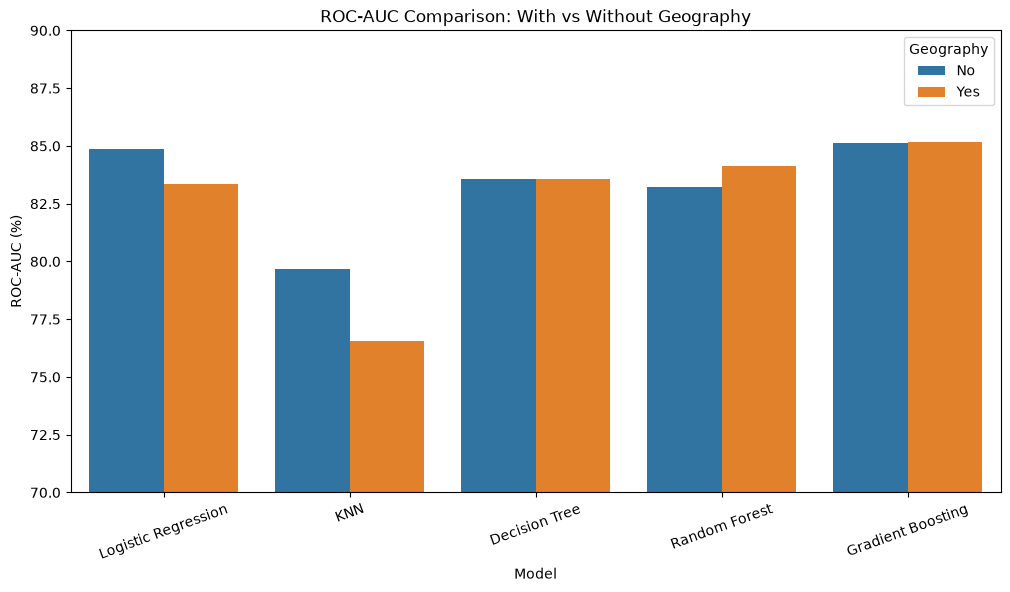

In [122]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results,
    x="Model",
    y="ROC_AUC",
    hue="Geography"
)

plt.title("ROC-AUC Comparison: With vs Without Geography")
plt.ylabel("ROC-AUC (%)")
plt.xlabel("Model")
plt.ylim(70, 90)
plt.xticks(rotation=20)
plt.legend(title="Geography")

plt.show()

In [123]:
geo_improved_df = ml_df.drop(
    columns=["City", "Zip Code", "Lat Long"]
)

geo_improved_df.shape

(7043, 22)

In [124]:
target = "Churn Label"

X_C = geo_improved_df.drop(columns=[target])
y_C = geo_improved_df[target]

print("X_C shape:", X_C.shape)
print("y_C shape:", y_C.shape)

X_C shape: (7043, 21)
y_C shape: (7043,)


In [125]:
X_C_train, X_C_test, y_C_train, y_C_test = train_test_split(
    X_C,
    y_C,
    test_size=0.20,
    random_state=42,
    stratify=y_C
)

print("Training:", X_C_train.shape)
print("Testing:", X_C_test.shape)

Training: (5634, 21)
Testing: (1409, 21)


In [126]:
X_C_train["Total Charges"] = pd.to_numeric(
    X_C_train["Total Charges"],
    errors="coerce"
)

X_C_test["Total Charges"] = pd.to_numeric(
    X_C_test["Total Charges"],
    errors="coerce"
)

In [127]:
numeric_features_C = X_C_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features_C = X_C_train.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print("Numerical features:")
print(numeric_features_C)

print("\nCategorical features:")
print(categorical_features_C)

Numerical features:
['Latitude', 'Longitude', 'Tenure Months', 'Monthly Charges', 'Total Charges']

Categorical features:
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


In [128]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_transformer_C = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer_C = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_C = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_C, numeric_features_C),
        ("cat", categorical_transformer_C, categorical_features_C)
    ]
)

In [129]:
X_C_train_processed = preprocessor_C.fit_transform(X_C_train)
X_C_test_processed = preprocessor_C.transform(X_C_test)

print("Processed training shape:", X_C_train_processed.shape)
print("Processed testing shape:", X_C_test_processed.shape)

Processed training shape: (5634, 48)
Processed testing shape: (1409, 48)


In [130]:
from sklearn.linear_model import LogisticRegression

logistic_C = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_C.fit(
    X_C_train_processed,
    y_C_train
)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [131]:
y_C_pred = logistic_C.predict(X_C_test_processed)
y_C_prob = logistic_C.predict_proba(X_C_test_processed)[:, 1]

In [132]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

print("Accuracy :", accuracy_score(y_C_test, y_C_pred))
print("Precision:", precision_score(y_C_test, y_C_pred, pos_label="Yes"))
print("Recall   :", recall_score(y_C_test, y_C_pred, pos_label="Yes"))
print("F1 Score :", f1_score(y_C_test, y_C_pred, pos_label="Yes"))
print("ROC-AUC  :", roc_auc_score(
    (y_C_test == "Yes").astype(int),
    y_C_prob
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_C_test, y_C_pred))

Accuracy : 0.801277501774308
Precision: 0.6407185628742516
Recall   : 0.5721925133689839
F1 Score : 0.6045197740112994
ROC-AUC  : 0.847901004934253

Confusion Matrix:
[[915 120]
 [160 214]]


In [133]:
from sklearn.ensemble import GradientBoostingClassifier

gradient_C = GradientBoostingClassifier(
    random_state=42
)

gradient_C.fit(
    X_C_train_processed,
    y_C_train
)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [134]:
y_C_gb_pred = gradient_C.predict(X_C_test_processed)
y_C_gb_prob = gradient_C.predict_proba(X_C_test_processed)[:, 1]

In [135]:
print("Accuracy :", accuracy_score(y_C_test, y_C_gb_pred))
print("Precision:", precision_score(y_C_test, y_C_gb_pred, pos_label="Yes"))
print("Recall   :", recall_score(y_C_test, y_C_gb_pred, pos_label="Yes"))
print("F1 Score :", f1_score(y_C_test, y_C_gb_pred, pos_label="Yes"))
print("ROC-AUC  :", roc_auc_score(
    (y_C_test == "Yes").astype(int),
    y_C_gb_prob
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_C_test, y_C_gb_pred))

Accuracy : 0.7991483321504613
Precision: 0.6472491909385113
Recall   : 0.5347593582887701
F1 Score : 0.5856515373352855
ROC-AUC  : 0.847376579090134

Confusion Matrix:
[[926 109]
 [174 200]]


In [136]:
city_stats = df.groupby("City").agg(
    Customers=("CustomerID", "count"),
    Churned=("Churn Value", "sum")
)

city_stats["Churn Rate"] = (
    city_stats["Churned"] / city_stats["Customers"] * 100
)

city_stats = city_stats.sort_values(
    "Customers",
    ascending=False
)

city_stats.head(20)

,Customers,Churned,Churn Rate
City,,,
Los Angeles,305,90,29.508197
San Diego,150,50,33.333333
San Jose,112,29,25.892857
Sacramento,108,26,24.074074
San Francisco,104,31,29.807692
Fresno,64,16,25.000000
Long Beach,60,15,25.000000
Oakland,52,13,25.000000
Stockton,44,12,27.272727


In [137]:
city_stats["Customers"].describe()

count    1129.000000
mean        6.238264
std        12.254863
min         4.000000
25%         4.000000
50%         4.000000
75%         5.000000
max       305.000000
Name: Customers, dtype: float64

In [138]:
thresholds = [10, 20, 30, 50, 100]

for threshold in thresholds:
    count = (city_stats["Customers"] >= threshold).sum()
    print(f"Cities with at least {threshold} customers: {count}")

Cities with at least 10 customers: 112
Cities with at least 20 customers: 35
Cities with at least 30 customers: 15
Cities with at least 50 customers: 8
Cities with at least 100 customers: 5


In [139]:
reliable_cities = city_stats[
    city_stats["Customers"] >= 20
].copy()

reliable_cities = reliable_cities.sort_values(
    "Churn Rate",
    ascending=False
)

reliable_cities.head(20)

,Customers,Churned,Churn Rate
City,,,
Santa Rosa,24,11,45.833333
North Hollywood,20,9,45.000000
Modesto,28,12,42.857143
Santa Barbara,28,10,35.714286
San Diego,150,50,33.333333
Glendale,40,13,32.500000
Torrance,25,8,32.000000
Pasadena,30,9,30.000000
San Francisco,104,31,29.807692


In [140]:
print("Model A preprocessor exists:", "preprocessor_A" in globals())
print("Model A training data exists:", "X_A_train" in globals())
print("Model A target exists:", "y_A_train" in globals())
print("Model C preprocessor exists:", "preprocessor_C" in globals())

Model A preprocessor exists: True
Model A training data exists: True
Model A target exists: True
Model C preprocessor exists: True


In [141]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

# Connect preprocessing and the classifier
gradient_pipeline_A = Pipeline(steps=[
    ("preprocessor", preprocessor_A),
    ("model", GradientBoostingClassifier(random_state=42))
])

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score, pos_label="Yes", zero_division=0
    ),
    "recall": make_scorer(
        recall_score, pos_label="Yes", zero_division=0
    ),
    "f1": make_scorer(
        f1_score, pos_label="Yes", zero_division=0
    ),
    "roc_auc": "roc_auc"
}

cv_results_A = cross_validate(
    gradient_pipeline_A,
    X_A_train,
    y_A_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

for metric in scoring:
    scores = cv_results_A[f"test_{metric}"]
    print(
        f"{metric.upper():10s}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

ACCURACY  : 0.8081 ± 0.0114
PRECISION : 0.6664 ± 0.0301
RECALL    : 0.5565 ± 0.0199
F1        : 0.6063 ± 0.0208
ROC_AUC   : 0.8629 ± 0.0105


In [142]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__n_estimators": [100, 150],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3],
    "model__min_samples_leaf": [5, 10]
}

grid_search = GridSearchCV(
    estimator=gradient_pipeline_A,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_A_train, y_A_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation ROC-AUC:")
print(round(grid_search.best_score_, 4))

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best parameters:
{'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__min_samples_leaf': 10, 'model__n_estimators': 100}

Best cross-validation ROC-AUC:
0.8644


In [143]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Best pipeline selected by GridSearchCV
best_model = grid_search.best_estimator_

# Predict on the held-out test set
y_test_pred = best_model.predict(X_A_test)
y_test_prob = best_model.predict_proba(X_A_test)[:, 1]

print("Accuracy :", round(accuracy_score(y_A_test, y_test_pred), 4))
print("Precision:", round(precision_score(
    y_A_test, y_test_pred, pos_label="Yes"
), 4))
print("Recall   :", round(recall_score(
    y_A_test, y_test_pred, pos_label="Yes"
), 4))
print("F1 Score :", round(f1_score(
    y_A_test, y_test_pred, pos_label="Yes"
), 4))
print("ROC-AUC  :", round(roc_auc_score(
    (y_A_test == "Yes").astype(int), y_test_prob
), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_A_test, y_test_pred, labels=["No", "Yes"]
))

print("\nClassification Report:")
print(classification_report(
    y_A_test, y_test_pred, zero_division=0
))

Accuracy : 0.8048
Precision: 0.6701
Recall   : 0.5214
F1 Score : 0.5865
ROC-AUC  : 0.8539

Confusion Matrix:
[[939  96]
 [179 195]]

Classification Report:
              precision    recall  f1-score   support

          No       0.84      0.91      0.87      1035
         Yes       0.67      0.52      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.80      1409



In [144]:

import pandas as pd
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score

# Get out-of-fold churn probabilities from the training data
oof_probabilities = cross_val_predict(
    best_model,
    X_A_train,
    y_A_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

# Find the column corresponding to "Yes"
yes_index = list(best_model.classes_).index("Yes")
oof_churn_prob = oof_probabilities[:, yes_index]

threshold_results = []

for threshold in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55]:
    predictions = [
        "Yes" if probability >= threshold else "No"
        for probability in oof_churn_prob
    ]

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_A_train, predictions, pos_label="Yes", zero_division=0
        ),
        "Recall": recall_score(
            y_A_train, predictions, pos_label="Yes", zero_division=0
        ),
        "F1 Score": f1_score(
            y_A_train, predictions, pos_label="Yes", zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
print(threshold_df.round(3).to_string(index=False))


 Threshold  Precision  Recall  F1 Score
      0.25      0.525   0.828     0.643
      0.30      0.556   0.784     0.650
      0.35      0.592   0.732     0.655
      0.40      0.616   0.673     0.643
      0.45      0.642   0.614     0.628
      0.50      0.674   0.546     0.603
      0.55      0.714   0.479     0.573


In [145]:

from sklearn.inspection import permutation_importance

importance_result = permutation_importance(
    best_model,
    X_A_test,
    y_A_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_A_test.columns,
    "Importance": importance_result.importances_mean,
    "Std": importance_result.importances_std
})

importance_df = importance_df.sort_values(
    "Importance", ascending=False
)

print(importance_df.head(15).round(4).to_string(index=False))


          Feature  Importance    Std
         Contract      0.0519 0.0035
    Tenure Months      0.0504 0.0020
       Dependents      0.0347 0.0060
 Internet Service      0.0068 0.0045
  Online Security      0.0053 0.0017
     Tech Support      0.0052 0.0014
  Monthly Charges      0.0046 0.0031
   Payment Method      0.0030 0.0010
Paperless Billing      0.0027 0.0012
          Partner      0.0021 0.0006
   Multiple Lines      0.0017 0.0010
    Total Charges      0.0013 0.0011
 Streaming Movies      0.0013 0.0002
    Online Backup      0.0011 0.0011
   Senior Citizen      0.0001 0.0001


In [146]:

from pathlib import Path
import joblib
import json

models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(best_model, models_dir / "churn_model.joblib")

with open(models_dir / "model_config.json", "w") as file:
    json.dump({"decision_threshold": 0.35}, file, indent=4)

print("Model and configuration saved successfully.")
print("Model classes:", list(best_model.classes_))


Model and configuration saved successfully.
Model classes: ['No', 'Yes']


In [147]:
from pathlib import Path
import joblib
import json

model_path = Path("../models/churn_model.joblib")
config_path = Path("../models/model_config.json")

print("Model exists:", model_path.exists())
print("Config exists:", config_path.exists())

if model_path.exists():
    loaded_model = joblib.load(model_path)
    print("Model classes:", list(loaded_model.classes_))

if config_path.exists():
    with open(config_path, "r") as file:
        config = json.load(file)
    print("Configuration:", config)


Model exists: True
Config exists: True
Model classes: ['No', 'Yes']
Configuration: {'decision_threshold': 0.35}
